# EASE trên dữ liệu thật — thứ tự nhân quả ở đuôi phân phối của 20 cổ phiếu HOSE

Notebook này áp dụng thuật toán **EASE** (*Extremal Ancestral SEarch*, Gnecco, Meinshausen, Peters & Engelke, 2021,
*Ann. Statist.* 49(3), `Paper/1. Causal discovery in heavy-tailed models.pdf`) cho lợi suất của VHM, NVL, STB, VPB, HPG,
rồi so với các phương pháp đối chứng (baseline) mà bài báo dùng: **Pairwise LiNGAM**, **ICA-LiNGAM**, **Rank PC** và **thứ tự ngẫu nhiên**.
Kiểm chứng cài đặt và độ nhạy với biên độ ±7% nằm ở `01_ease_simulation.ipynb`; tổng hợp phát hiện ở `Processing_finding.ipynb`.

**Câu hỏi.** Khi một mã có cú sốc cực trị (tăng/giảm rất mạnh), cú sốc đó có "lan" sang mã khác không, và theo chiều nào?

**Ý tưởng của EASE.** Nếu $X_j$ gây ra $X_k$ (qua SCM tuyến tính, nhiễu đuôi dày cùng chỉ số $\alpha$) thì mọi giá trị
cực lớn của $X_j$ kéo theo giá trị cực lớn của $X_k$, còn chiều ngược lại thì không. Hệ số nhân quả đuôi đo điều đó:

$$\Gamma_{jk} = \lim_{u\to 1^-}\mathbb{E}\big[F_k(X_k)\,\big|\,F_j(X_j) > u\big],\qquad
\Psi_{jk} = \lim_{u\to 1^-}\mathbb{E}\big[\sigma(F_k(X_k))\,\big|\,\sigma(F_j(X_j)) > u\big],\ \ \sigma(v)=|2v-1|,$$

$F_j$: hàm phân phối của $X_j$. $\Gamma$ chỉ nhìn đuôi trên; $\Psi$ nhìn cả hai đuôi (và cả hệ số âm). Đọc kết quả theo Bảng 2 của bài báo:

| $\Psi_{12}$ | $\Psi_{21}$ | Kết luận |
|---|---|---|
| $=1$ | $\in(1/2,1)$ | $X_1$ gây ra $X_2$ |
| $\in(1/2,1)$ | $=1$ | $X_2$ gây ra $X_1$ |
| $\in(1/2,1)$ | $\in(1/2,1)$ | có nguyên nhân chung, không nhân quả trực tiếp |
| $=1/2$ | $=1/2$ | không liên hệ |

**Các bước:** (1) lọc GARCH; (2) kiểm tra giả định đuôi dày; (3) ước lượng $\hat\Psi$, chạy EASE; (4) bootstrap;
(5) độ nhạy theo số quan sát đuôi $k$; (6) các biến thể dữ liệu và đuôi; (7) baseline.

## 0. Thiết lập

Nạp module dùng chung: `eda_utils` (CSDL, style hình), `causal_tail` (hệ số đuôi, EASE, SID), `causal_baselines`
(LiNGAM, Rank PC), `tail_preprocessing` (GARCH, GPD, bootstrap). Lấy lợi suất log ngày $r_{i,t}$ trong khung phân tích
chung (từ 01/06/2018) và lợi suất tuần (tổng lợi suất log 5 phiên, chỉ giữ tuần cả 20 mã đều có phiên).

In [1]:
import sys, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sql").is_dir() and (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import eda_utils as U
import causal_tail as CT
import causal_baselines as CB
import tail_preprocessing as TP

U.apply_publication_style()
pd.set_option("display.float_format", "{:,.3f}".format)
SYMBOLS, COL, PAL = U.SYMBOLS, U.SYMBOL_COLORS, U.PALETTE
FOLDER = "processing"                      # hình → report/figure/processing, bảng → report/table/processing
METHOD_COLORS = {"EASE": PAL["blue_main"], "Pairwise LiNGAM": PAL["red_strong"], "ICA-LiNGAM": PAL["green_3"],
                 "Rank PC": PAL["violet"], "Ngẫu nhiên": PAL["neutral"]}

con = U.connect()
r = con.execute("SELECT * FROM v_returns_wide").df().set_index("time")[SYMBOLS].dropna()
r.index = pd.to_datetime(r.index)
weekly = r.resample("W-FRI").sum()[(r.resample("W-FRI").count() > 0).all(axis=1)]
print(f"Lợi suất ngày: T = {len(r)} phiên ({r.index[0]:%d/%m/%Y} → {r.index[-1]:%d/%m/%Y}); tuần: {len(weekly)} tuần")

Lợi suất ngày: T = 2118 phiên (05/06/2018 → 25/11/2026); tuần: 439 tuần


## 1. Lọc GARCH — đưa dữ liệu về gần độc lập cùng phân phối

**Tính gì:** với mỗi mã, khớp GARCH(1,1) với nhiễu Student-t rồi lấy phần dư chuẩn hoá $z_{i,t}$.

**Công thức.**
$$r_{i,t} = \mu_i + \sigma_{i,t}\,z_{i,t},\qquad \sigma_{i,t}^2 = \omega_i + a_i\,(r_{i,t-1}-\mu_i)^2 + b_i\,\sigma_{i,t-1}^2,\qquad z_{i,t}\sim t_{\nu_i}\ \text{(chuẩn hoá)}.$$
$a_i + b_i$: độ bền (persistence) của biến động; $\nu_i$: bậc tự do của nhiễu.

**Vì sao:** EDA (phát hiện 5) cho thấy hiệu ứng ARCH mạnh — các phiên cực trị đi theo cụm. Định lý 2 của bài báo cần các
quan sát độc lập; nếu không lọc, $k$ phiên cực trị lớn nhất có thể chỉ đến từ 1–2 đợt khủng hoảng. Lọc GARCH cũng có lợi phụ:
mức trần/sàn ±7% trở thành $\pm 7\%/\sigma_{i,t}$ — thay đổi theo ngày, nên các quan sát **không còn dồn đúng một giá trị**.

**Các bước:** (1) khớp mô hình (`arch`); (2) kiểm định Ljung–Box ($m=10$) cho $r_t^2$ và $z_t^2$; (3) lưu $z$ vào
`data/processed/garch_std_resid.parquet`.

In [2]:
from statsmodels.stats.diagnostic import acorr_ljungbox

z, garch_params = TP.garch_standardize(r)
z = z.dropna()
lb = pd.DataFrame({s: {"LB(10) p của r²": acorr_ljungbox(r[s] ** 2, lags=[10])["lb_pvalue"].iloc[0],
                       "LB(10) p của z²": acorr_ljungbox(z[s] ** 2, lags=[10])["lb_pvalue"].iloc[0],
                       "LB(10) p của z": acorr_ljungbox(z[s], lags=[10])["lb_pvalue"].iloc[0]} for s in SYMBOLS}).T
garch_params["omega (×1e-4)"] = garch_params["omega"].astype(float) * 1e4      # phương sai, đơn vị lợi suất gốc
garch_tab = pd.concat([garch_params[["omega (×1e-4)", "alpha[1]", "beta[1]", "persistence", "nu", "converged"]], lb], axis=1)
U.save_table(garch_tab, "02_garch_params", FOLDER)
z.to_parquet(ROOT / "data" / "processed" / "garch_std_resid.parquet")

n_cap = {s: (r[s].abs() >= 0.065).sum() for s in SYMBOLS}
print(f"Số phiên |r| ≥ 6,5% (gần trần/sàn) so với 2k = {2 * CT.default_k(len(r))} phiên cực trị EASE dùng:", n_cap)
garch_tab

Số phiên |r| ≥ 6,5% (gần trần/sàn) so với 2k = 42 phiên cực trị EASE dùng: {'VCB': np.int64(17), 'BID': np.int64(51), 'CTG': np.int64(46), 'TCB': np.int64(49), 'MBB': np.int64(36), 'STB': np.int64(80), 'VPB': np.int64(59), 'VIC': np.int64(78), 'VHM': np.int64(75), 'NVL': np.int64(95), 'KDH': np.int64(39), 'VNM': np.int64(18), 'MSN': np.int64(42), 'SAB': np.int64(24), 'MWG': np.int64(56), 'GAS': np.int64(61), 'PLX': np.int64(53), 'HPG': np.int64(39), 'FPT': np.int64(21), 'SSI': np.int64(96)}


,omega (×1e-4),alpha[1],beta[1],persistence,nu,converged,LB(10) p của r²,LB(10) p của z²,LB(10) p của z
VCB,0.261,0.236,0.722,0.958,3.591,True,0.000,0.795,0.831
BID,0.118,0.119,0.868,0.987,4.151,True,0.000,0.949,0.422
CTG,0.120,0.122,0.869,0.991,3.804,True,0.000,0.794,0.402
TCB,0.201,0.109,0.860,0.969,3.643,True,0.000,0.508,0.037
MBB,0.155,0.134,0.845,0.978,3.656,True,0.000,0.550,0.741
STB,0.138,0.116,0.873,0.989,4.266,True,0.000,0.813,0.810
VPB,0.082,0.090,0.903,0.993,4.082,True,0.000,0.373,0.016
VIC,0.129,0.261,0.739,1.000,3.120,True,0.000,0.316,0.049
VHM,0.155,0.160,0.840,1.000,3.331,True,0.000,0.538,0.152
NVL,0.038,0.133,0.867,1.000,4.059,True,0.000,0.284,0.001


### Phân tích


- Biến động **rất bền**: $a_i + b_i$ = 0,90 (VNM) đến 1,00 (VIC, VHM, NVL, KDH, GAS — sát IGARCH); bậc tự do nhiễu $\nu$ = 3,1–4,7: phần dư vẫn đuôi dày.
- Lọc có hiệu quả: Ljung–Box của $r^2$ có p ≈ 0 ở cả 20 mã, của $z^2$ không còn ý nghĩa — **hết hiệu ứng ARCH**. Một số mã còn tự tương quan bậc một nhẹ ở mức
  trung bình ($z$ của NVL, VPB, TCB, VIC, MSN có p < 0,05), ít ảnh hưởng tới phân tích đuôi.
- Số phiên $|r| \ge 6{,}5\%$ từ 17 (VCB) đến 96 (SSI); ở 12/20 mã con số này **vượt** $2k = 42$ — trên $r$ thô, tập cực trị chủ yếu là phiên trần/sàn.
  Trên $z$, cực trị được xếp theo mức bất thường so với biến động lúc đó.

## 2. Kiểm tra giả định: nhiễu đuôi dày với chỉ số đuôi chung

**Tính gì:** tham số hình dạng $\xi$ của phân phối Pareto tổng quát (GPD) cho phần vượt ngưỡng phân vị 95%, đuôi trên và đuôi dưới,
trên ba biến thể dữ liệu: lợi suất ngày $r$, phần dư GARCH $z$, lợi suất tuần — như mục 5.2 của bài báo.

**Công thức.** Với ngưỡng $u$ và $Y = X - u \mid X > u$:
$$P(Y \le y) = 1 - \Big(1 + \xi\,\frac{y}{\beta}\Big)^{-1/\xi},\qquad \widehat{\mathrm{SE}}(\hat\xi)\approx\frac{1+\hat\xi}{\sqrt{n_u}}\ \text{(Coles, 2001)},$$
$n_u$: số quan sát vượt ngưỡng. $\xi>0$ ⇔ đuôi dày dạng Pareto với chỉ số đuôi $\alpha = 1/\xi$; $\xi = 0$: đuôi mũ (như chuẩn);
$\xi<0$: đuôi **bị chặn** (có cận trên hữu hạn).

**Đọc kết quả:** EASE cần $\xi>0$ (đuôi dày) và các mã có $\xi$ **gần nhau** (khoảng $\hat\xi\pm2\,\mathrm{SE}$ chồng lên nhau).
Đường đứt nét đánh dấu $\xi=0$.

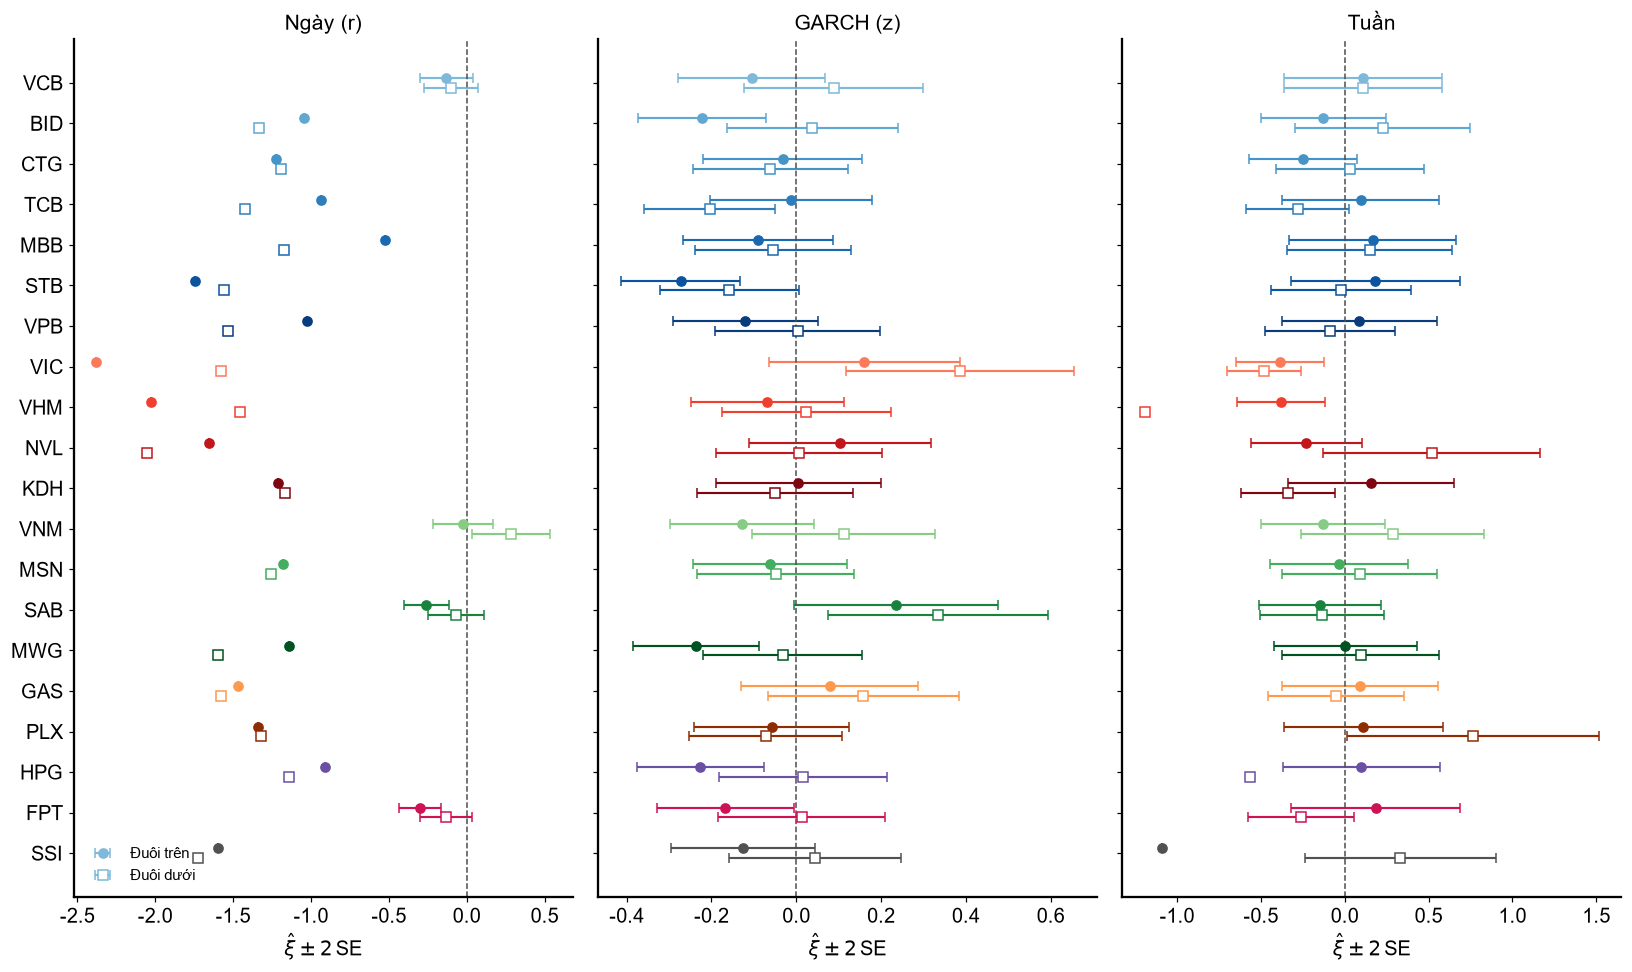

bien_the GARCH (z)        Ngày (r)          Tuần       
duoi          dưới   trên     dưới   trên   dưới   trên
ma                                                     
VCB          0.088 -0.105   -0.100 -0.130  0.107  0.107
BID          0.038 -0.222   -1.336 -1.044  0.226 -0.127
CTG         -0.061 -0.032   -1.190 -1.228  0.031 -0.247
TCB         -0.204 -0.012   -1.425 -0.938 -0.281  0.094
MBB         -0.054 -0.090   -1.172 -0.525  0.148  0.166
STB         -0.158 -0.273   -1.555 -1.743 -0.024  0.181
VPB          0.003 -0.121   -1.531 -1.028 -0.089  0.087
VIC          0.386  0.160   -1.579 -2.378 -0.480 -0.385
VHM          0.024 -0.068   -1.456 -2.027 -1.191 -0.381
NVL          0.006  0.103   -2.054 -1.656  0.519 -0.229
KDH         -0.051  0.005   -1.170 -1.210 -0.340  0.156
VNM          0.112 -0.128    0.285 -0.024  0.285 -0.132
MSN         -0.048 -0.062   -1.255 -1.181  0.088 -0.035
SAB          0.334  0.235   -0.070 -0.259 -0.134 -0.145
MWG         -0.033 -0.236   -1.596 -1.144  0.095  0.003
GAS          0.158  0.078   -1.578 -1.469 -0.050  0.092
PLX         -0.072 -0.058   -1.318 -1.343  0.762  0.110
HPG          0.016 -0.226   -1.138 -0.912 -0.567  0.098
FPT          0.013 -0.167   -0.132 -0.299 -0.259  0.184
SSI          0.044 -0.125   -1.728 -1.598  0.332 -1.088

In [3]:
variants = {"Ngày (r)": r, "GARCH (z)": z, "Tuần": weekly}
rows = []
for vname, X in variants.items():
    for s in SYMBOLS:
        for tail, up in (("trên", True), ("dưới", False)):
            g = TP.gpd_tail_shape(X[s].values, q=0.95, upper=up)
            rows.append({"bien_the": vname, "ma": s, "duoi": tail, "xi": g["xi"], "se": g["se"], "n_vuot": g["n_exc"]})
gpd = pd.DataFrame(rows)
U.save_table(gpd.set_index(["bien_the", "ma", "duoi"]), "02_gpd_shape", FOLDER)

fig, axes = plt.subplots(1, 3, figsize=(15, 9), sharey=True)
for ax, vname in zip(axes, variants):
    d = gpd[gpd.bien_the == vname]
    for t, (tail, mk, dx) in enumerate((("trên", "o", -0.12), ("dưới", "s", 0.12))):
        dd = d[d.duoi == tail]
        for i, s in enumerate(SYMBOLS):
            row = dd[dd.ma == s].iloc[0]
            ax.errorbar(row.xi, i + dx, xerr=0 if np.isnan(row.se) else 2 * row.se, fmt=mk, color=COL[s], ms=6, capsize=3, lw=1.4,
                        mfc=COL[s] if tail == "trên" else "white", label=f"Đuôi {tail}" if i == 0 else None)
    ax.axvline(0, color=PAL["gray_dark"], ls="--", lw=1)
    ax.set_yticks(range(len(SYMBOLS)), SYMBOLS); ax.invert_yaxis()
    ax.set_xlabel(r"$\hat\xi \pm 2\,$SE"); ax.set_title(vname)
axes[0].legend(loc="lower left", fontsize=10)
U.finalize_figure(fig, "02_gpd_shape", folder=FOLDER); plt.show()
gpd.pivot_table(index="ma", columns=["bien_the", "duoi"], values="xi").loc[SYMBOLS]

### Phân tích


- **Lợi suất ngày thô:** $\hat\xi$ từ −0,5 đến −2,4 ở 16/20 mã (đuôi **bị chặn**); chỉ các mã ít chạm biên (VCB, VNM, SAB, FPT) có $\hat\xi$ gần 0.
- **Phần dư GARCH $z$:** $\hat\xi$ từ −0,27 đến +0,39; đa số không khác 0, vài mã dương rõ (VIC đuôi dưới 0,39; SAB 0,33/0,24). Giả định **chỉ số đuôi chung**
  chấp nhận được ở mức thô, giả định **đuôi Pareto** ($\xi > 0$) chỉ thoả ở một phần các mã.
- Hệ quả: kết luận EASE trên dữ liệu thật mang tính gợi ý; mô phỏng (notebook 01) cho biết sai số kỳ vọng khi $\alpha \approx 3$.

## 3. Ma trận $\hat\Psi$ và thứ tự nhân quả EASE

**Tính gì:** ước lượng $\hat\Psi_{jk}$ cho 380 cặp có thứ tự trên phần dư GARCH $z$, với $k = \lfloor n^{0,4}\rfloor$ như bài báo.

**Công thức** (ước lượng thực nghiệm, công thức (8) và mục 4.1 của bài báo):
$$\hat F_k(x) = \frac1n\sum_{i=1}^n \mathbb 1\{X_{ik}\le x\},\qquad
\hat\Psi_{jk} = \frac{1}{2k}\Big[\sum_{i\in\mathcal U_j}\sigma\big(\hat F_k(X_{ik})\big) + \sum_{i\in\mathcal L_j}\sigma\big(\hat F_k(X_{ik})\big)\Big],$$
$\mathcal U_j$ ($\mathcal L_j$): chỉ số của $k$ phiên có $X_j$ lớn nhất (nhỏ nhất). Phiên trùng giá trị tại ngưỡng được chọn ngẫu nhiên (seed cố định).

**EASE** (mục 3.1): ở bước $s$, với mỗi nút $i$ còn lại tính $M_i = \max_{j\neq i}\hat\Psi_{ji}$ — mức độ $i$ "bị" một nút khác
kéo theo ở đuôi; chọn nút có $M_i$ **nhỏ nhất** làm gốc, bỏ nó ra, lặp lại. Kết quả là một **thứ tự nhân quả** (gốc trước):
nó nói "mã đứng sau không gây ra mã đứng trước", **không** khẳng định mã trước gây ra mã sau.

**Ma trận bất đối xứng** $D_{jk} = \hat\Psi_{jk} - \hat\Psi_{kj}$: $D_{jk} > 0$ là dấu hiệu (yếu) cho chiều $j \to k$.

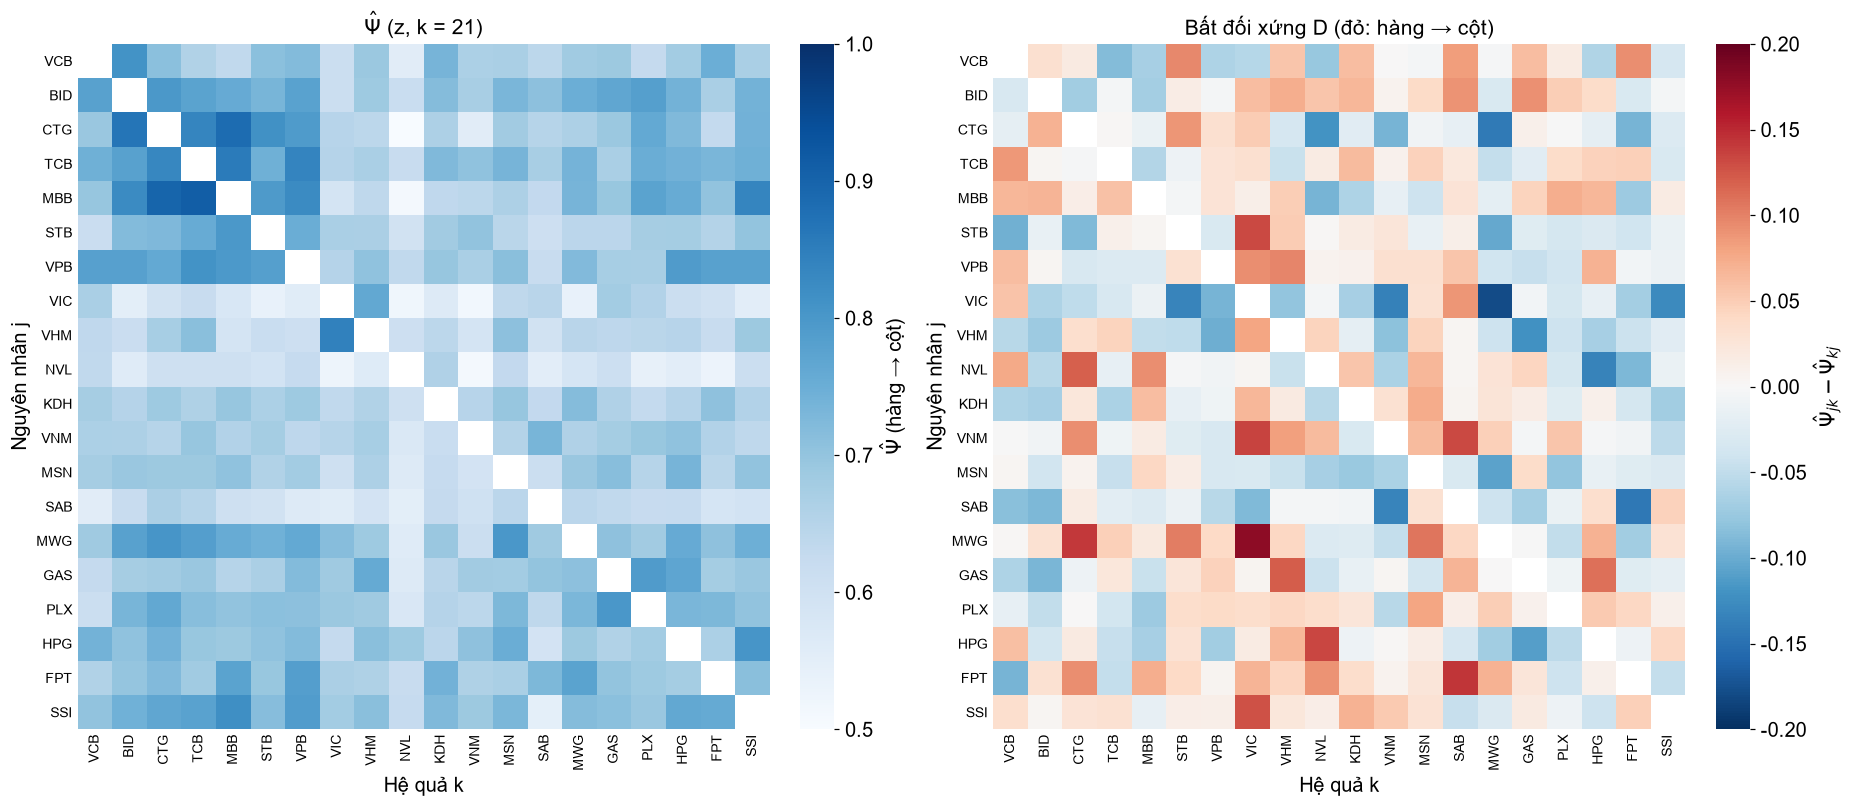

Thứ tự nhân quả EASE (gốc → lá): NVL → VNM → SAB → KDH → VHM → VIC → MWG → MSN → FPT → VCB → PLX → GAS → HPG → STB → SSI → VPB → BID → MBB → CTG → TCB


,chon,VCB,BID,CTG,TCB,MBB,STB,VPB,VIC,VHM,...,KDH,VNM,MSN,SAB,MWG,GAS,PLX,HPG,FPT,SSI
buoc,,,,,,,,,,,,,,,,,,,,,
1,NVL,0.781,0.867,0.897,0.912,0.883,0.814,0.836,0.842,0.763,...,0.742,0.705,0.800,0.733,0.775,0.799,0.790,0.791,0.778,0.835
2,VNM,0.781,0.867,0.897,0.912,0.883,0.814,0.836,0.842,0.763,...,0.742,0.705,0.800,0.733,0.775,0.799,0.790,0.791,0.778,0.835
3,SAB,0.781,0.867,0.897,0.912,0.883,0.814,0.836,0.842,0.763,...,0.742,NaN,0.800,0.728,0.775,0.799,0.790,0.791,0.778,0.835
4,KDH,0.781,0.867,0.897,0.912,0.883,0.814,0.836,0.842,0.763,...,0.742,NaN,0.800,NaN,0.775,0.799,0.790,0.791,0.778,0.835
5,VHM,0.781,0.867,0.897,0.912,0.883,0.814,0.836,0.842,0.763,...,NaN,NaN,0.800,NaN,0.775,0.799,0.790,0.791,0.778,0.835
6,VIC,0.781,0.867,0.897,0.912,0.883,0.814,0.836,0.715,NaN,...,NaN,NaN,0.800,NaN,0.775,0.799,0.790,0.791,0.778,0.835
7,MWG,0.781,0.867,0.897,0.912,0.883,0.814,0.836,NaN,NaN,...,NaN,NaN,0.800,NaN,0.775,0.799,0.790,0.791,0.778,0.835
8,MSN,0.781,0.867,0.897,0.912,0.883,0.814,0.836,NaN,NaN,...,NaN,NaN,0.751,NaN,NaN,0.799,0.790,0.791,0.778,0.835
9,FPT,0.781,0.867,0.897,0.912,0.883,0.814,0.836,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0.799,0.790,0.791,0.778,0.835


In [4]:
n = len(z); K = CT.default_k(n)
Psi = CT.tail_coef_matrix(z, k=K, kind="psi")
D = Psi - Psi.T
order_main = CT.ease(Psi)
path = CT.ease_scores_path(Psi)
U.save_table(Psi, "02_psi_matrix", FOLDER); U.save_table(path, "02_ease_path", FOLDER)

fig, axes = plt.subplots(1, 2, figsize=(17, 7.5))
U.make_heatmap(axes[0], Psi, cmap="Blues", vmin=0.5, vmax=1, fmt=None, tick_fontsize=9, cbar_label=r"$\hat\Psi$ (hàng → cột)",
               title=rf"$\hat\Psi$ (z, k = {K})")
U.make_heatmap(axes[1], D, cmap="RdBu_r", vmin=-0.2, vmax=0.2, fmt=None, tick_fontsize=9, cbar_label=r"$\hat\Psi_{jk}-\hat\Psi_{kj}$",
               title="Bất đối xứng D (đỏ: hàng → cột)")
for ax in axes:
    ax.set_xlabel("Hệ quả k"); ax.set_ylabel("Nguyên nhân j")
U.finalize_figure(fig, "02_psi_matrix", folder=FOLDER); plt.show()
print("Thứ tự nhân quả EASE (gốc → lá):", " → ".join(order_main))
path

### Phân tích


- $\overline{\hat\Psi}$ = 0,681 trên 380 cặp (0,49–0,91); **cùng ngành 0,73 > khác ngành 0,67**. Lớn nhất đều trong ngân hàng: MBB→TCB 0,91, MBB→CTG 0,90,
  CTG→MBB 0,88, CTG→BID 0,87; ngoài ngân hàng có VHM→VIC 0,84 (cùng tập đoàn Vingroup).
- Không cặp nào đạt 1 ở cả hai chiều theo cách Bảng 2 đòi hỏi cho nhân quả trực tiếp; đa số cặp có cả hai hệ số trong (1/2, 1) — mẫu hình **nguyên nhân chung**.
- **Thứ tự EASE:** NVL → VNM → SAB → KDH → VHM → VIC → MWG → MSN → FPT → VCB → PLX → GAS → HPG → STB → SSI → VPB → BID → MBB → CTG → TCB.
  Đầu danh sách là bất động sản và tiêu dùng; **cuối danh sách gần như toàn ngân hàng** (và SSI). "Gốc" nghĩa là *ít bị mã khác kéo theo*,
  không phải *gây ra mã khác*.

## 4. Bootstrap: thứ tự EASE ổn định đến đâu?

**Tính gì:** lấy mẫu lại có hoàn lại $B = 500$ lần **theo dòng** (giữ nguyên quan hệ đồng thời giữa 20 mã trong cùng phiên — hợp lệ
vì $z$ gần độc lập theo thời gian sau khi lọc GARCH), mỗi lần tính lại $\hat\Psi^{(b)}$ và thứ tự EASE $\hat\pi^{(b)}$.

**Đầu ra:** (a) tần suất mỗi mã đứng ở vị trí 1…5; (b) khoảng tin cậy bootstrap 90% (phân vị 5%–95%) của $D_{jk}$ —
cặp nào có khoảng không chứa 0 thì chiều bất đối xứng là đáng tin ở mức 10%.

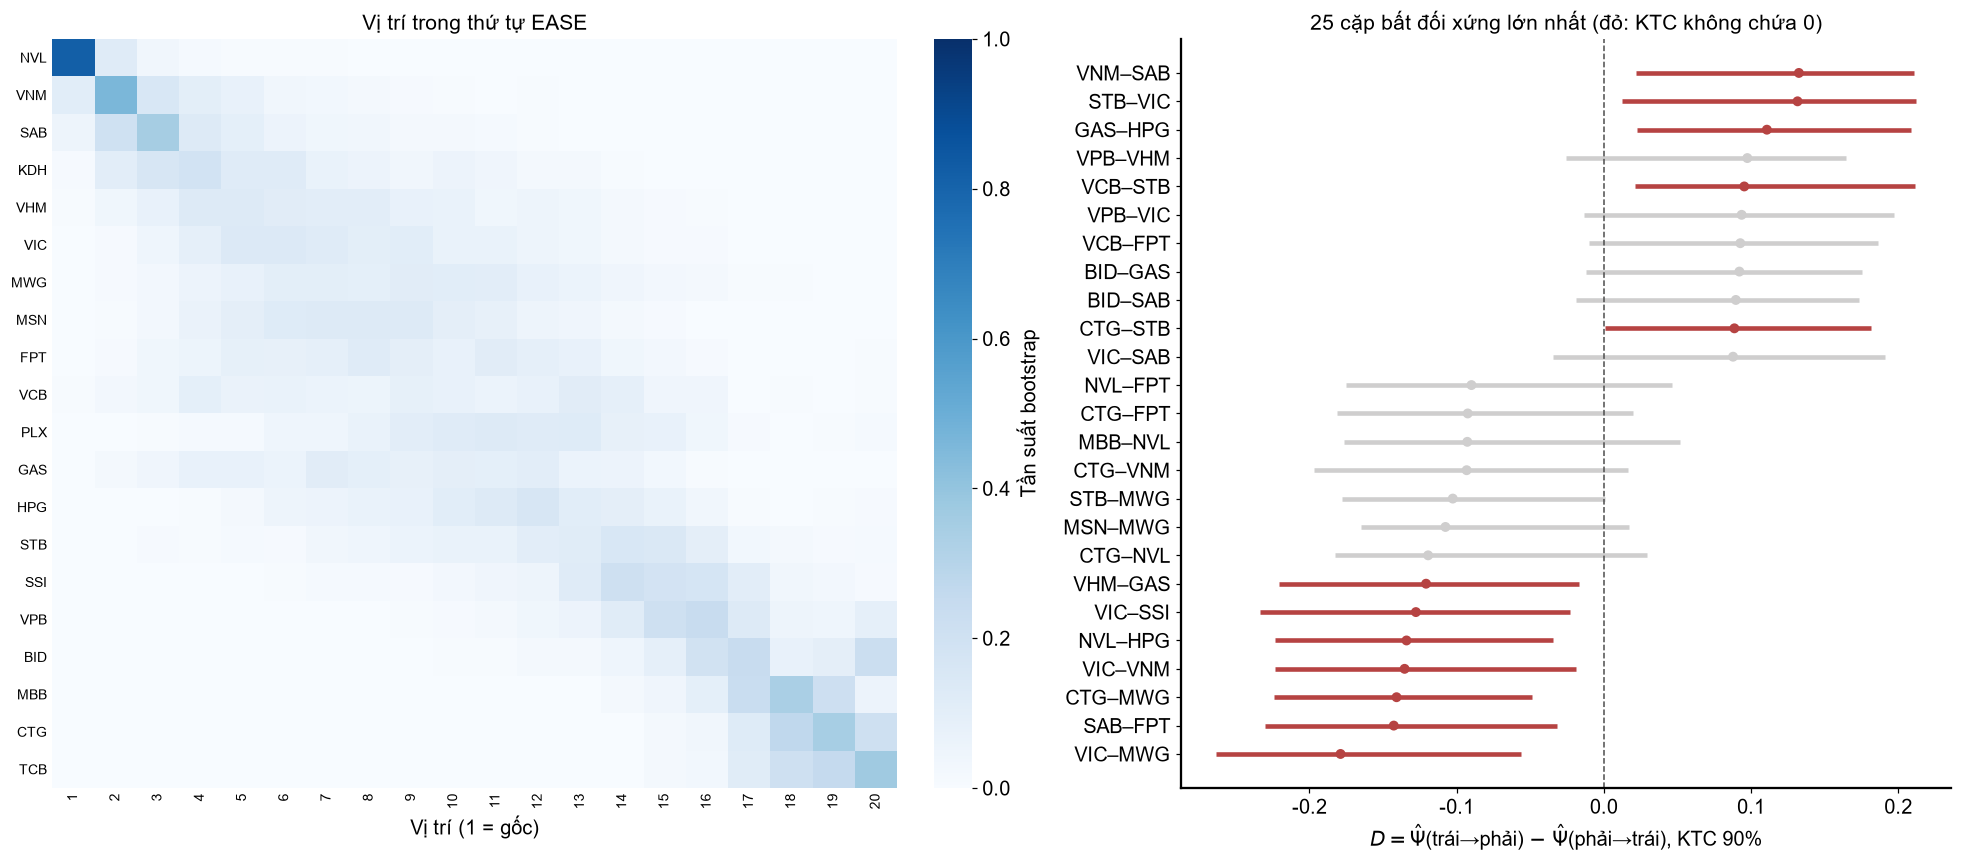

Tỷ lệ bootstrap cho đúng thứ tự ['NVL', 'VNM', 'SAB', 'KDH', 'VHM', 'VIC', 'MWG', 'MSN', 'FPT', 'VCB', 'PLX', 'GAS', 'HPG', 'STB', 'SSI', 'VPB', 'BID', 'MBB', 'CTG', 'TCB']: 0.0%


,cap,D,q05,q95,co_y_nghia_10pct
0,VCB–BID,0.031,-0.044,0.140,False
1,VCB–CTG,0.019,-0.067,0.159,False
2,VCB–TCB,-0.087,-0.158,0.029,False
3,VCB–MBB,-0.066,-0.121,0.075,False
4,VCB–STB,0.095,0.021,0.211,True
...,...,...,...,...,...
185,PLX–FPT,0.042,-0.047,0.129,False
186,PLX–SSI,0.010,-0.106,0.086,False
187,HPG–FPT,-0.011,-0.115,0.099,False
188,HPG–SSI,0.041,-0.077,0.120,False


In [5]:
B = 500
boot = TP.bootstrap_coef(z, k=K, kind="psi", B=B, seed=2026)
orders = [CT.ease(pd.DataFrame(m, index=SYMBOLS, columns=SYMBOLS)) for m in boot]
rank_freq = pd.DataFrame(0.0, index=SYMBOLS, columns=range(1, len(SYMBOLS) + 1))
for o in orders:
    for pos, s in enumerate(o, 1):
        rank_freq.loc[s, pos] += 1 / B
same_as_main = np.mean([o == order_main for o in orders])

pairs = [(a, b) for i, a in enumerate(SYMBOLS) for b in SYMBOLS[i + 1:]]
iu = {s: i for i, s in enumerate(SYMBOLS)}
diff = pd.DataFrame([{"cap": f"{a}–{b}", "D": D.loc[a, b],
                      "q05": np.quantile(boot[:, iu[a], iu[b]] - boot[:, iu[b], iu[a]], 0.05),
                      "q95": np.quantile(boot[:, iu[a], iu[b]] - boot[:, iu[b], iu[a]], 0.95)} for a, b in pairs])
diff["co_y_nghia_10pct"] = (diff.q05 > 0) | (diff.q95 < 0)
U.save_table(rank_freq, "02_bootstrap_rank_freq", FOLDER); U.save_table(diff.set_index("cap"), "02_bootstrap_asymmetry", FOLDER)

fig, axes = plt.subplots(1, 2, figsize=(18, 8), gridspec_kw={"width_ratios": [1.2, 1]})
rf = rank_freq.loc[order_main]
U.make_heatmap(axes[0], rf, cmap="Blues", vmin=0, vmax=1, fmt=None, tick_fontsize=9, cbar_label="Tần suất bootstrap",
               title="Vị trí trong thứ tự EASE")
axes[0].set_xlabel("Vị trí (1 = gốc)"); axes[0].set_ylabel("")
d = diff.reindex(diff.D.abs().sort_values(ascending=False).index).head(25).sort_values("D")
y = np.arange(len(d))
colors = [PAL["red_strong"] if sig else PAL["neutral"] for sig in d.co_y_nghia_10pct]
axes[1].hlines(y, d.q05, d.q95, color=colors, lw=3)
axes[1].scatter(d.D, y, color=colors, zorder=3, s=30)
axes[1].axvline(0, color=PAL["gray_dark"], ls="--", lw=1)
axes[1].set_yticks(y, d.cap); axes[1].set_xlabel(r"$D = \hat\Psi$(trái→phải) $-\ \hat\Psi$(phải→trái), KTC 90%")
axes[1].set_title("25 cặp bất đối xứng lớn nhất (đỏ: KTC không chứa 0)")
U.finalize_figure(fig, "02_bootstrap_stability", folder=FOLDER); plt.show()
print(f"Tỷ lệ bootstrap cho đúng thứ tự {order_main}: {same_as_main:.1%}")
diff.round(3)

### Phân tích


- Với 20 mã, thứ tự đầy đủ không bao giờ lặp lại nguyên vẹn trong 500 mẫu bootstrap (0%) — điều tất yếu khi có $20!$ hoán vị.
- **Cấu trúc thô thì ổn định:** NVL làm gốc ở **82%** mẫu (VNM 11%, SAB 5%); vị trí trung bình tăng dần theo nhóm: NVL 1,3 · VNM 3,1 · SAB 3,9 · KDH 5,6 … ·
  BID 17,2 · MBB 17,7 · CTG 18,5 · TCB 18,7. Vị trí cuối thuộc TCB (37%), BID (22%), CTG (21%).
- **14/190 cặp** có bất đối xứng đáng tin ở mức 10% (khoảng 90% không chứa 0) — **ít hơn** con số kỳ vọng do ngẫu nhiên (~19 cặp khi không hiệu chỉnh
  nhiều kiểm định). Không nên đọc từng cặp như bằng chứng nhân quả.

## 5. Độ nhạy theo số quan sát đuôi $k$

**Tính gì:** chạy lại EASE với $k_n = \lfloor n^{\nu}\rfloor$, $\nu \in \{0{,}20; 0{,}25; \ldots; 0{,}70\}$ (giống Hình 6 của bài báo)
và vẽ $\hat\Psi$ hai chiều của các cặp có bất đối xứng lớn nhất kèm dải bootstrap 90% ($B=200$ mỗi $\nu$).

**Ý tưởng:** $k$ nhỏ → chỉ dùng cực trị thật (ít chệch, nhiều nhiễu); $k$ lớn → dùng cả phần "thân" phân phối (ổn định nhưng chệch
về hành vi trung bình). Kết luận đáng tin khi **không đổi** trên một dải $\nu$ rộng.

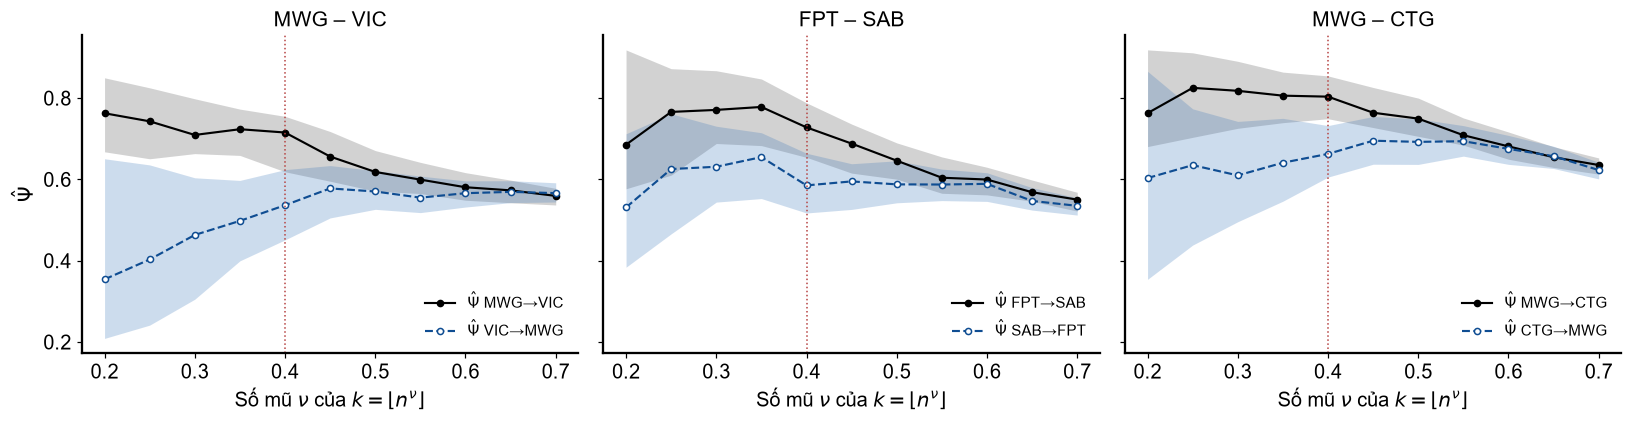

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
ν=0.20 (k=4),NVL,KDH,VNM,VHM,VIC,GAS,SAB,STB,HPG,MSN,SSI,FPT,MBB,TCB,VPB,CTG,BID,VCB,PLX,MWG
ν=0.25 (k=6),NVL,VNM,SAB,KDH,VHM,VIC,VCB,FPT,SSI,BID,HPG,MWG,MSN,STB,GAS,PLX,VPB,MBB,CTG,TCB
ν=0.30 (k=9),NVL,VNM,SAB,VHM,VIC,KDH,FPT,STB,VCB,BID,HPG,MWG,MSN,SSI,GAS,PLX,VPB,MBB,TCB,CTG
ν=0.35 (k=14),NVL,VNM,VCB,VHM,VIC,SAB,FPT,KDH,HPG,PLX,GAS,MWG,MSN,STB,VPB,SSI,MBB,TCB,CTG,BID
ν=0.40 (k=21),NVL,VNM,SAB,KDH,VHM,VIC,MWG,MSN,FPT,VCB,PLX,GAS,HPG,STB,SSI,VPB,BID,MBB,CTG,TCB
ν=0.45 (k=31),NVL,VNM,SAB,MSN,MWG,KDH,GAS,PLX,VHM,VIC,FPT,VCB,HPG,SSI,STB,VPB,TCB,BID,MBB,CTG
ν=0.50 (k=46),NVL,SAB,VNM,KDH,MSN,FPT,VHM,VIC,MWG,GAS,PLX,VCB,SSI,HPG,STB,VPB,TCB,BID,CTG,MBB
ν=0.55 (k=67),NVL,SAB,VNM,MSN,KDH,VCB,VHM,VIC,GAS,PLX,FPT,MWG,HPG,SSI,STB,VPB,BID,MBB,CTG,TCB
ν=0.60 (k=98),NVL,VNM,SAB,KDH,MSN,VCB,FPT,MWG,VHM,VIC,HPG,GAS,PLX,SSI,STB,VPB,BID,MBB,CTG,TCB
ν=0.65 (k=145),NVL,SAB,VNM,KDH,MSN,VCB,FPT,MWG,VIC,VHM,GAS,PLX,HPG,SSI,STB,VPB,BID,CTG,MBB,TCB


In [6]:
nus = np.round(np.arange(0.20, 0.701, 0.05), 2)
order_by_nu = {}
for nu in nus:
    order_by_nu[nu] = CT.ease(CT.tail_coef_matrix(z, k=CT.default_k(n, nu), kind="psi"))
order_nu_tab = pd.DataFrame({f"ν={nu:.2f} (k={CT.default_k(n, nu)})": o for nu, o in order_by_nu.items()},
                            index=range(1, len(SYMBOLS) + 1)).T
U.save_table(order_nu_tab, "02_order_by_k", FOLDER)

top_pairs = diff.reindex(diff.D.abs().sort_values(ascending=False).index).head(3)
top_pairs = [tuple(c.split("–")) if row.D > 0 else tuple(c.split("–")[::-1])
             for c, row in zip(top_pairs.cap, top_pairs.itertuples())]
curves = {pr: {"fwd": [], "bwd": [], "fwd_lo": [], "fwd_hi": [], "bwd_lo": [], "bwd_hi": []} for pr in top_pairs}
for nu in nus:
    kk = CT.default_k(n, nu)
    M = CT.tail_coef_matrix(z, k=kk, kind="psi")
    bt = TP.bootstrap_coef(z, k=kk, kind="psi", B=200, seed=int(nu * 100))
    for a, b in top_pairs:
        f_, b_ = bt[:, iu[a], iu[b]], bt[:, iu[b], iu[a]]
        c = curves[(a, b)]
        c["fwd"].append(M.loc[a, b]); c["bwd"].append(M.loc[b, a])
        c["fwd_lo"].append(np.quantile(f_, 0.05)); c["fwd_hi"].append(np.quantile(f_, 0.95))
        c["bwd_lo"].append(np.quantile(b_, 0.05)); c["bwd_hi"].append(np.quantile(b_, 0.95))

fig, axes = plt.subplots(1, len(top_pairs), figsize=(5 * len(top_pairs), 4), sharey=True)
for ax, (a, b) in zip(np.atleast_1d(axes), top_pairs):
    c = curves[(a, b)]
    ax.fill_between(nus, c["fwd_lo"], c["fwd_hi"], color=PAL["gray_dark"], alpha=0.25, lw=0)
    ax.fill_between(nus, c["bwd_lo"], c["bwd_hi"], color=PAL["blue_secondary"], alpha=0.25, lw=0)
    ax.plot(nus, c["fwd"], "o-", color="black", ms=4, lw=1.4, label=rf"$\hat\Psi$ {a}→{b}")
    ax.plot(nus, c["bwd"], "o--", color=PAL["blue_main"], mfc="white", ms=4, lw=1.4, label=rf"$\hat\Psi$ {b}→{a}")
    ax.axvline(0.4, color=PAL["red_strong"], ls=":", lw=1)
    ax.set_xlabel(r"Số mũ $\nu$ của $k=\lfloor n^{\nu}\rfloor$"); ax.set_title(f"{a} – {b}"); ax.legend(fontsize=10, loc="lower right")
np.atleast_1d(axes)[0].set_ylabel(r"$\hat\Psi$")
U.finalize_figure(fig, "02_k_sensitivity", folder=FOLDER); plt.show()
order_nu_tab

### Phân tích


- **NVL là gốc với mọi $\nu$** từ 0,20 đến 0,70; các vị trí cuối chủ yếu là ngân hàng (BID, MBB, CTG, TCB, VPB) với $\nu \ge 0{,}25$.
- Các vị trí giữa thay đổi theo $k$; cấu trúc "phi ngân hàng trước, ngân hàng sau" thì không đổi.
- Hệ số của các cặp bất đối xứng lớn nhất hội tụ về ~0,6 khi $\nu \to 0{,}7$: với $k$ lớn, "đuôi" lẫn vào thân và chỉ còn phản ánh tương quan chung.

## 6. Biến thể dữ liệu và đuôi: đuôi trên, đuôi dưới, lợi suất thô, lợi suất tuần

**Tính gì:** thứ tự EASE với 3 loại hệ số × 3 biến thể dữ liệu:
- $\hat\Psi$ (hai đuôi); $\hat\Gamma$ (chỉ đuôi trên: cú tăng mạnh); $\hat\Gamma^-$ (chỉ đuôi dưới: cú **sập** — $\hat\Gamma$ áp dụng cho $-X$):
$$\hat\Gamma^-_{jk} = \frac1k\sum_{i\in\mathcal L_j}\big(1-\hat F_k(X_{ik})\big).$$
- Dữ liệu: $z$ (chính), $r$ thô (bị chặn ±7%, có cụm biến động), lợi suất tuần (ít bị chặn hơn, nhưng $n$ chỉ còn ~440, $k=11$).

**So sánh hai thứ tự** bằng độ đồng thuận cặp $\mathrm{agr}(\pi,\pi') = \frac{1}{\binom p2}\sum_{i<j}\mathbb 1\{\text{hai thứ tự xếp } i,j \text{ cùng chiều}\}$
(= 1 − khoảng cách Kendall chuẩn hoá; 1: trùng nhau, 0: đảo ngược hoàn toàn, ~0,5: không liên quan).

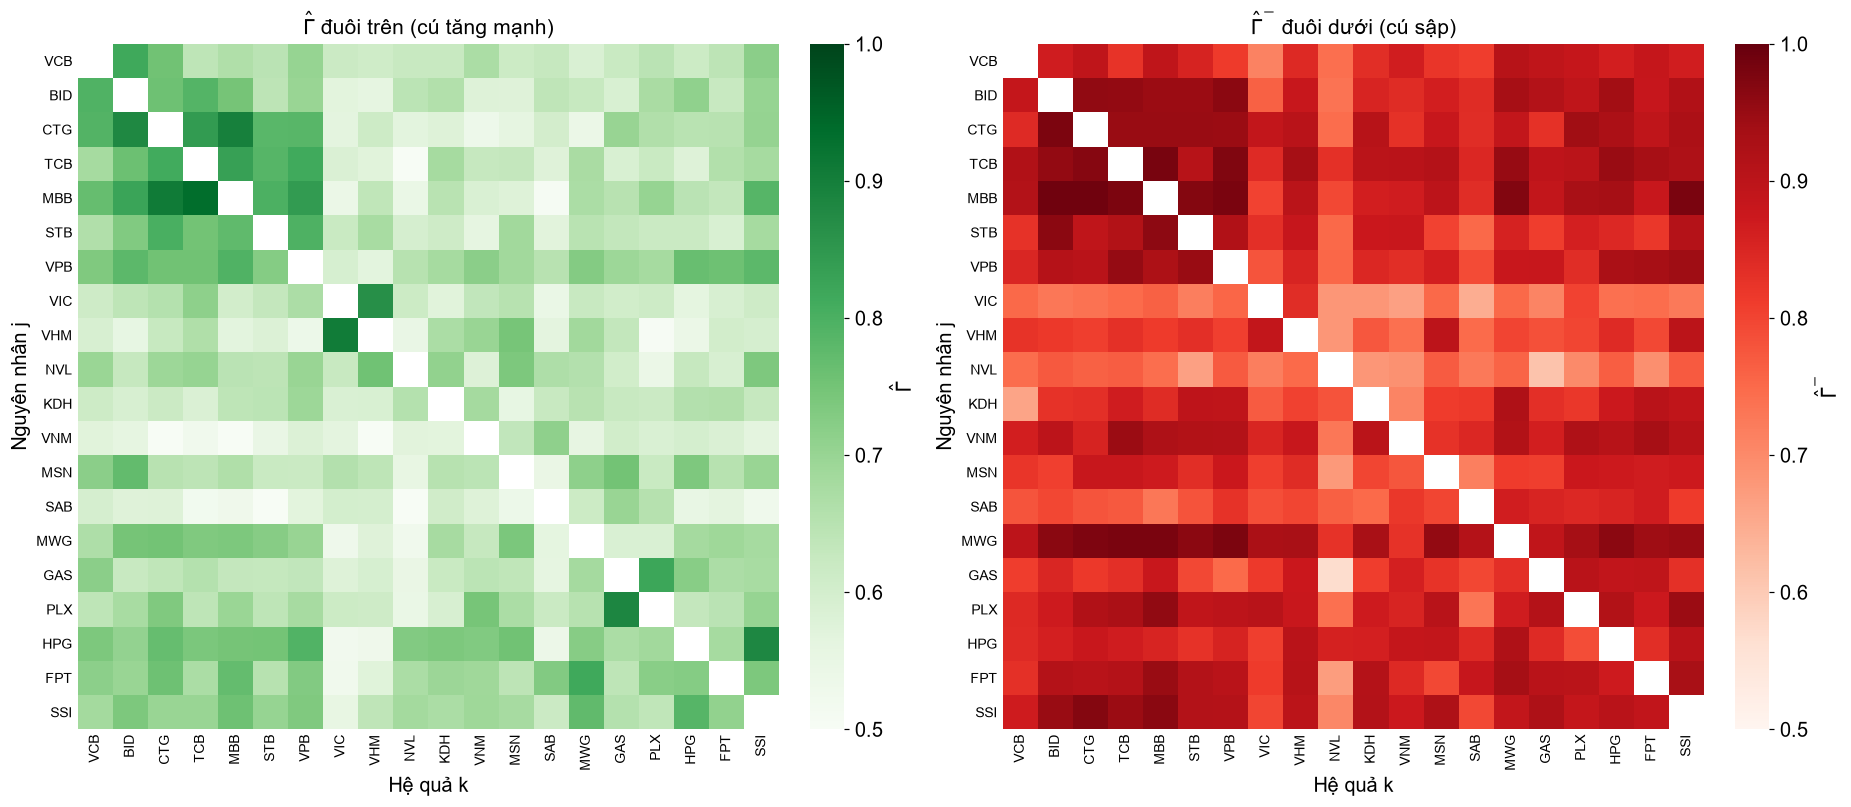

Trung bình ngoài đường chéo: Γ̂ trên = 0.656, Γ̂⁻ dưới = 0.853


,Thứ tự EASE,Đồng thuận với chính
Ngày (r) | Ψ (hai đuôi),NVL → VNM → MSN → SAB → VIC → VHM → KDH → VCB ...,0.884
Ngày (r) | Γ (đuôi trên),NVL → SAB → VNM → VIC → VHM → KDH → FPT → GAS ...,0.884
Ngày (r) | Γ⁻ (đuôi dưới),NVL → SAB → MSN → VNM → KDH → VIC → VCB → VHM ...,0.874
GARCH (z) | Ψ (hai đuôi),NVL → VNM → SAB → KDH → VHM → VIC → MWG → MSN ...,1.000
GARCH (z) | Γ (đuôi trên),NVL → SAB → KDH → VNM → MSN → FPT → MWG → HPG ...,0.826
GARCH (z) | Γ⁻ (đuôi dưới),NVL → VNM → SAB → VCB → GAS → VIC → KDH → VHM ...,0.821
Tuần | Ψ (hai đuôi),SAB → NVL → FPT → MSN → VNM → VIC → VHM → MWG ...,0.826
Tuần | Γ (đuôi trên),SAB → NVL → VNM → MSN → MWG → PLX → VHM → VIC ...,0.811
Tuần | Γ⁻ (đuôi dưới),NVL → SAB → VNM → VIC → VHM → FPT → KDH → MWG ...,0.868


In [7]:
kinds = {"Ψ (hai đuôi)": "psi", "Γ (đuôi trên)": "gamma_upper", "Γ⁻ (đuôi dưới)": "gamma_lower"}
var_orders = {}
for vname, X in variants.items():
    for kname, kind in kinds.items():
        var_orders[(vname, kname)] = CT.ease(CT.tail_coef_matrix(X, k=CT.default_k(len(X)), kind=kind))
var_tab = pd.DataFrame({f"{v} | {k}": " → ".join(o) for (v, k), o in var_orders.items()}, index=["Thứ tự EASE"]).T
var_tab["Đồng thuận với chính"] = [TP.order_agreement(o, order_main) for o in var_orders.values()]
U.save_table(var_tab, "02_order_variants", FOLDER)

Gl = CT.tail_coef_matrix(z, k=K, kind="gamma_lower"); Gu = CT.tail_coef_matrix(z, k=K, kind="gamma_upper")
fig, axes = plt.subplots(1, 2, figsize=(17, 7.5))
U.make_heatmap(axes[0], Gu, cmap="Greens", vmin=0.5, vmax=1, fmt=None, tick_fontsize=9, cbar_label=r"$\hat\Gamma$", title=r"$\hat\Gamma$ đuôi trên (cú tăng mạnh)")
U.make_heatmap(axes[1], Gl, cmap="Reds", vmin=0.5, vmax=1, fmt=None, tick_fontsize=9, cbar_label=r"$\hat\Gamma^{-}$", title=r"$\hat\Gamma^{-}$ đuôi dưới (cú sập)")
for ax in axes:
    ax.set_xlabel("Hệ quả k"); ax.set_ylabel("Nguyên nhân j")
U.finalize_figure(fig, "02_upper_vs_lower", folder=FOLDER); plt.show()
off = ~np.eye(len(SYMBOLS), dtype=bool)
print(f"Trung bình ngoài đường chéo: Γ̂ trên = {Gu.values[off].mean():.3f}, Γ̂⁻ dưới = {Gl.values[off].mean():.3f}")
var_tab

### Phân tích


- **Đuôi dưới mạnh hơn hẳn đuôi trên:** $\bar\Gamma^-$ = 0,853 so với $\bar\Gamma$ = 0,656 — cú **sập** lan rộng hơn cú tăng, nhất quán với EDA
  (phụ thuộc đuôi dưới vượt mức Gaussian ở 190/190 cặp).
- **Thứ tự vững qua 9 biến thể:** NVL đứng đầu ở 7/9 biến thể (SAB đầu ở hai biến thể lợi suất tuần); đồng thuận với cấu hình chính 0,81–0,88 (1,0 với chính nó).
  Lợi suất thô (bị chặn ±7%) cho kết quả gần giống $z$ (0,87–0,88).

## 7. So sánh với các baseline

**Tính gì:** chạy trên cùng dữ liệu $z$:

| Phương pháp | Ý tưởng | Đầu ra |
|---|---|---|
| **Pairwise LiNGAM** (DirectLiNGAM, độ đo `pwling`) | Mô hình tuyến tính, nhiễu không chuẩn; tìm biến ngoại sinh bằng tỷ số hợp lý cặp đôi | thứ tự |
| **ICA-LiNGAM** | Phân tích thành phần độc lập (ICA) của $X = (I-B)^{-1}\varepsilon$, hoán vị $B$ về tam giác dưới | thứ tự (đồng thuận 10 seed, cột xáo trộn) |
| **Rank PC** | Thuật toán PC (kiểm định độc lập có điều kiện), trên điểm chuẩn theo hạng, mức $5\cdot10^{-4}$ | CPDAG (lớp tương đương) |
| **Ngẫu nhiên** | Hoán vị đều | thứ tự (1000 lần) |

Khác biệt cốt lõi: LiNGAM/PC dùng **toàn bộ** phân phối (phần thân chiếm đa số), EASE chỉ dùng $2k = 42$ phiên cực trị của mỗi mã.
Không có "đáp án đúng" cho dữ liệu thật, nên ta đo **mức đồng thuận** giữa các phương pháp và **độ ổn định** của từng phương pháp.

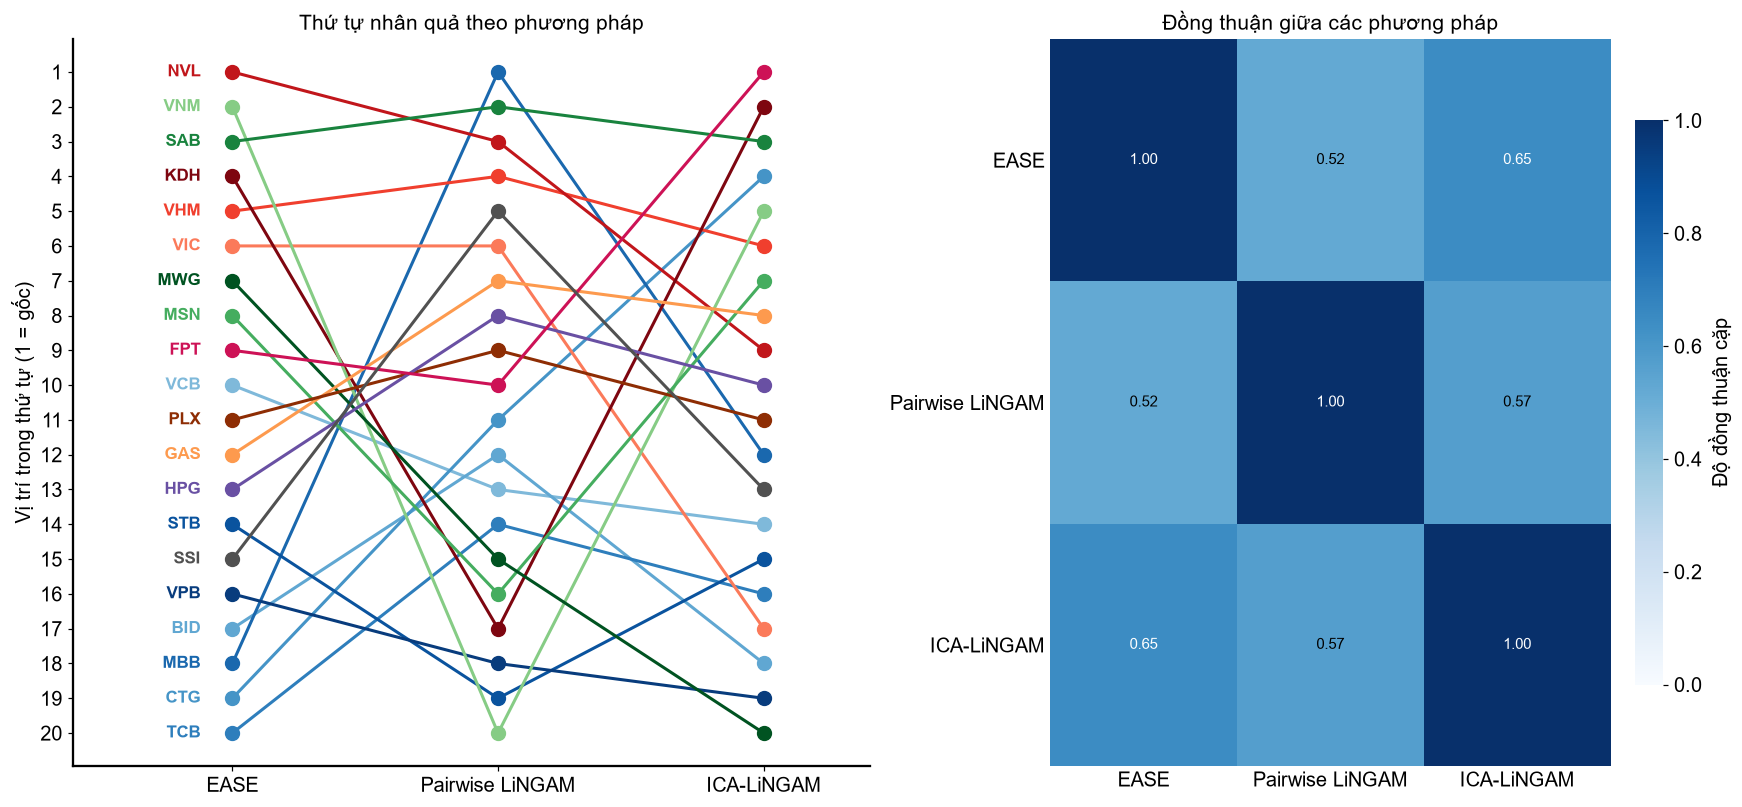

ICA-LiNGAM: đồng thuận cặp trung bình giữa 10 seed = 0.59
Rank PC (CPDAG): VCB → BID, VCB → VHM, VCB → VNM, VCB → SAB, BID → GAS, CTG → VCB, CTG → BID, CTG — TCB, CTG — VPB, CTG — SSI, TCB — VPB, TCB → VHM, TCB → MWG, MBB → BID, MBB → CTG, MBB → TCB, MBB → STB, MBB → VPB, MBB — HPG, MBB → SSI, STB → CTG, STB → TCB, STB → VPB, STB → SSI, VPB → MWG, VPB → SSI, VIC → NVL, VHM → VIC, VHM → KDH, VHM → MSN, VHM → SSI, NVL → KDH, KDH → MWG, KDH → SSI, VNM → STB, VNM → MSN, VNM → SAB, MSN → SAB, MSN → MWG, MSN → GAS, MSN → HPG, MWG → SSI, GAS — PLX, GAS — FPT, PLX → VNM, PLX — SSI, HPG → NVL, HPG → KDH, HPG — FPT, HPG → SSI, FPT → VCB, FPT → KDH, FPT → MWG
Đồng thuận của thứ tự ngẫu nhiên với EASE: trung bình 0.50, phân vị 95% = 0.63


,EASE,Pairwise LiNGAM,ICA-LiNGAM
EASE,1.000,0.521,0.647
Pairwise LiNGAM,0.521,1.000,0.568
ICA-LiNGAM,0.647,0.568,1.000


In [8]:
rng = np.random.default_rng(2026)
Z = z.to_numpy()
base_orders = {"EASE": order_main,
               "Pairwise LiNGAM": [SYMBOLS[i] for i in CB.run_pairwise_lingam(Z)["order"]]}
ica_idx, ica_pos = CB.ica_lingam_consensus(Z, seeds=range(10))            # cột xáo trộn theo seed, đồng thuận Borda
base_orders["ICA-LiNGAM"] = [SYMBOLS[i] for i in ica_idx]
ica_orders = [[SYMBOLS[i] for i in np.argsort(row)] for row in ica_pos]
pc_adj = CB.run_rank_pc(Z)["adj"]
pc_edges = [(SYMBOLS[i], SYMBOLS[j], "—" if pc_adj[j, i] else "→") for i in range(len(SYMBOLS)) for j in range(len(SYMBOLS))
            if pc_adj[i, j] and (i < j or not pc_adj[j, i])]
rand_agree = [TP.order_agreement(list(rng.permutation(SYMBOLS)), order_main) for _ in range(1000)]

names = list(base_orders)
agree = pd.DataFrame([[TP.order_agreement(base_orders[a], base_orders[b]) for b in names] for a in names],
                     index=names, columns=names)
U.save_table(agree, "02_baseline_agreement", FOLDER)
U.save_table(pd.DataFrame({m: o for m, o in base_orders.items()}, index=range(1, len(SYMBOLS) + 1)).T, "02_baseline_orders", FOLDER)

fig, axes = plt.subplots(1, 2, figsize=(16, 7.5), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
for s in SYMBOLS:
    ranks = [base_orders[m].index(s) + 1 for m in names]
    ax.plot(range(len(names)), ranks, "o-", color=COL[s], lw=2, ms=9)
    ax.text(-0.12, ranks[0], s, color=COL[s], ha="right", va="center", fontsize=11, fontweight="bold")
ax.set_xticks(range(len(names)), names); ax.set_yticks(range(1, len(SYMBOLS) + 1)); ax.invert_yaxis()
ax.set_ylabel("Vị trí trong thứ tự (1 = gốc)"); ax.set_title("Thứ tự nhân quả theo phương pháp")
ax.set_xlim(-0.6, len(names) - 0.6)
U.make_heatmap(axes[1], agree, cmap="Blues", vmin=0, vmax=1, cbar_label="Độ đồng thuận cặp",
               title="Đồng thuận giữa các phương pháp")
U.finalize_figure(fig, "02_baseline_comparison", folder=FOLDER); plt.show()

print(f"ICA-LiNGAM: đồng thuận cặp trung bình giữa 10 seed = "
      f"{np.mean([TP.order_agreement(a, b) for i, a in enumerate(ica_orders) for b in ica_orders[i + 1:]]):.2f}")
print("Rank PC (CPDAG):", ", ".join(f"{a} {e} {b}" for a, b, e in pc_edges) or "không có cạnh")
print(f"Đồng thuận của thứ tự ngẫu nhiên với EASE: trung bình {np.mean(rand_agree):.2f}, "
      f"phân vị 95% = {np.quantile(rand_agree, 0.95):.2f}")
agree

### Phân tích


- **Ba phương pháp KHÔNG đồng thuận** với 20 mã: EASE–Pairwise LiNGAM 0,52, EASE–ICA-LiNGAM 0,65, hai LiNGAM 0,57; mức nền của thứ tự ngẫu nhiên là 0,50
  (phân vị 95% = 0,63). Chỉ EASE–ICA vượt nhẹ mức ngẫu nhiên.
- **ICA-LiNGAM không ổn định:** đồng thuận trung bình giữa 10 seed chỉ 0,59. Ban đầu thứ tự ICA-LiNGAM bám theo **thứ tự cột đầu vào** (đã kiểm tra: đồng thuận
  0,81–0,90 với cột bị xáo trộn) — đã sửa bằng cách xáo trộn cột theo seed và lấy thứ tự đồng thuận Borda.
- Pairwise LiNGAM đặt MBB đầu tiên và VNM cuối — gần như **ngược** EASE ở nhóm ngân hàng. Hai phương pháp đo hai thứ khác nhau: LiNGAM dùng phần thân phân phối,
  nơi nhân tố chung (ngân hàng tải cao) chiếm ưu thế theo hướng "nguồn"; EASE dùng đuôi, nơi mã tải cao là mã "bị kéo theo" nhiều nhất.
- Rank PC trả về CPDAG với nhiều cạnh có hướng nhưng ở mức $5\cdot10^{-4}$ vẫn nối hầu hết các cặp — dấu hiệu nhân tố chung không quan sát được.

## 8. Kết luận


1. **Phụ thuộc đuôi mạnh, theo ngành:** $\overline{\hat\Psi}$ = 0,68, cùng ngành 0,73 > khác ngành 0,67; mạnh nhất trong ngân hàng và cặp VHM–VIC.
2. **Thứ tự EASE ổn định ở mức nhóm:** NVL làm gốc (82% bootstrap, mọi $k$), ngân hàng ở cuối. Thứ tự đầy đủ không ổn định.
3. **Cú sập lan mạnh hơn cú tăng** ($\bar\Gamma^-$ 0,85 so với $\bar\Gamma$ 0,66).
4. **Baseline không đồng thuận** với EASE ở 20 mã (0,52–0,65), khác hẳn kết quả 5 mã — phương pháp đuôi và phương pháp thân cho hai bức tranh khác nhau.
5. **Câu hỏi để kiểm chứng:** thứ tự "ít nhạy → nhạy với thị trường" gợi ý EASE đang xếp theo hệ số tải của một nhân tố chung — Validation kiểm tra trực tiếp.